In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/Churn_Modelling.csv')

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
df.info()
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

Missing Values:
RowNumber          0
CustomerId         0
Surname            0
CreditScore   

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Churn Rate by Geography:
Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64

Churn Rate by Gender:
Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64

Churn Rate by NumOfProducts:
NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00
Name: Exited, dtype: float64

Churn Rate by IsActiveMember:
IsActiveMember
0    26.85
1    14.27
Name: Exited, dtype: float64

Churn Rate by HasCrCard:
HasCrCard
0    20.81
1    20.18
Name: Exited, dtype: float64


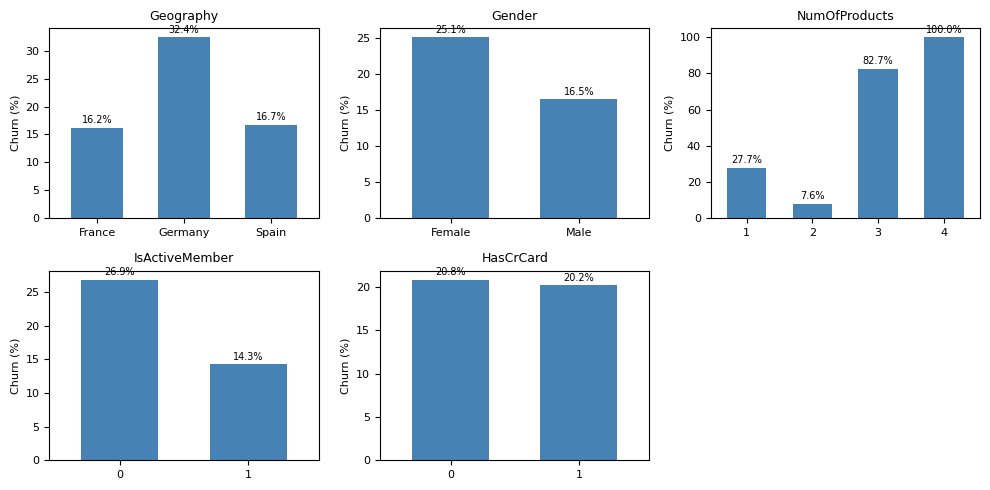

In [5]:
import matplotlib.pyplot as plt

categorical_cols = [
    'Geography', 'Gender', 'NumOfProducts',
    'IsActiveMember', 'HasCrCard'
]

fig, axes = plt.subplots(2, 3, figsize=(10, 5))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    rates = df.groupby(col)['Exited'].mean() * 100

    print(f"\nChurn Rate by {col}:")
    print(rates.round(2))

    rates.plot(kind='bar', ax=axes[i], color='steelblue', width=0.6)

    axes[i].set_title(col, fontsize=9)
    axes[i].set_ylabel('Churn (%)', fontsize=8)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='both', labelsize=8, rotation=0)

    for bars in axes[i].containers:
        axes[i].bar_label(bars, fmt='%.1f%%', fontsize=7, padding=2)

axes[-1].axis('off')
plt.tight_layout()
plt.show()

In [6]:
# Check customer counts and churn rates
for col in ['Geography', 'Gender', 'NumOfProducts', 'IsActiveMember']:
    summary = (
        df.groupby(col)['Exited']
        .agg(
            Total_Customers='count',
            Churned_Customers='sum',
            Churn_Rate='mean'
        )
    )

    summary['Churn_Rate'] = (
        summary['Churn_Rate'] * 100
    ).round(2)

    print(f"\n--- {col} ---")
    print(summary)


--- Geography ---
           Total_Customers  Churned_Customers  Churn_Rate
Geography                                                
France                5014                810       16.15
Germany               2509                814       32.44
Spain                 2477                413       16.67

--- Gender ---
        Total_Customers  Churned_Customers  Churn_Rate
Gender                                                
Female             4543               1139       25.07
Male               5457                898       16.46

--- NumOfProducts ---
               Total_Customers  Churned_Customers  Churn_Rate
NumOfProducts                                                
1                         5084               1409       27.71
2                         4590                348        7.58
3                          266                220       82.71
4                           60                 60      100.00

--- IsActiveMember ---
                Total_Customers  Chu

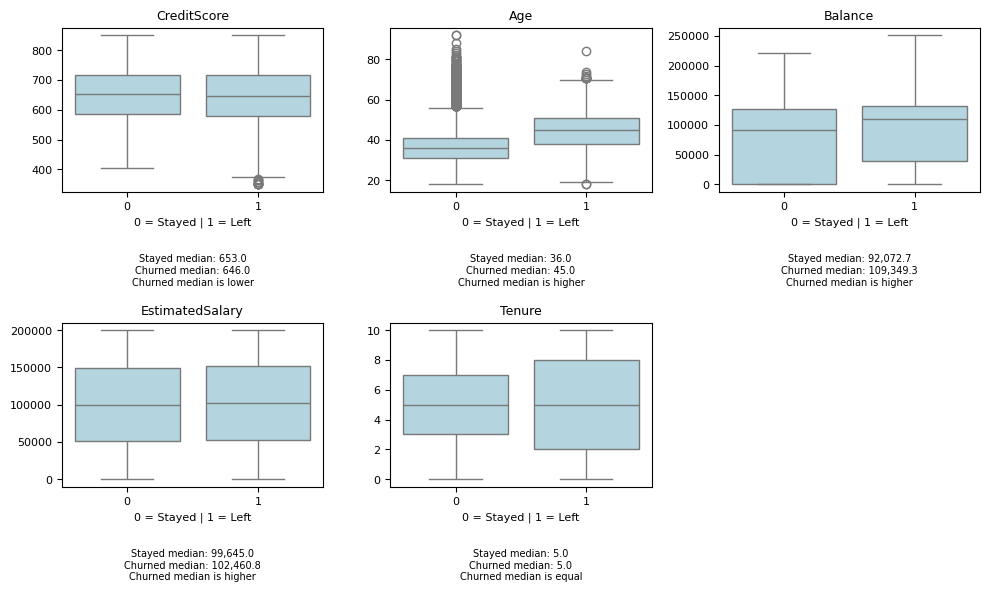

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = [
    'CreditScore',
    'Age',
    'Balance',
    'EstimatedSalary',
    'Tenure'
]

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    stayed = df.loc[df['Exited'] == 0, col]
    churned = df.loc[df['Exited'] == 1, col]

    sns.boxplot(
        data=df,
        x='Exited',
        y=col,
        ax=axes[i],
        color='lightblue'
    )

    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('0 = Stayed | 1 = Left', fontsize=8)
    axes[i].set_ylabel('')
    axes[i].tick_params(labelsize=8)

    stayed_median = stayed.median()
    churned_median = churned.median()
    difference = churned_median - stayed_median

    if difference > 0:
        comparison = "higher"
    elif difference < 0:
        comparison = "lower"
    else:
        comparison = "equal"

    description = (
        f"Stayed median: {stayed_median:,.1f}\n"
        f"Churned median: {churned_median:,.1f}\n"
        f"Churned median is {comparison}"
    )

    axes[i].text(
        0.5, -0.38,
        description,
        transform=axes[i].transAxes,
        ha='center',
        va='top',
        fontsize=7
    )

axes[-1].axis('off')

plt.tight_layout()
plt.subplots_adjust(hspace=0.8, bottom=0.18)
plt.show()

In [9]:
numerical_cols = [
    'CreditScore',
    'Age',
    'Balance',
    'EstimatedSalary',
    'Tenure'
]

summary = df.groupby('Exited')[numerical_cols].median().T

summary.columns = ['Stayed', 'Churned']
summary['Difference'] = summary['Churned'] - summary['Stayed']

print(summary.round(2))

                   Stayed    Churned  Difference
CreditScore        653.00     646.00       -7.00
Age                 36.00      45.00        9.00
Balance          92072.68  109349.29    17276.61
EstimatedSalary  99645.04  102460.84     2815.80
Tenure               5.00       5.00        0.00


In [10]:
from scipy.stats import mannwhitneyu

stayed_age = df.loc[df['Exited'] == 0, 'Age']
churned_age = df.loc[df['Exited'] == 1, 'Age']

statistic, p_value = mannwhitneyu(
    stayed_age,
    churned_age,
    alternative='two-sided'
)

print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Statistically significant difference in age.")
else:
    print("No statistically significant difference in age.")

P-value: 0.000000
Statistically significant difference in age.


In [11]:
from scipy.stats import mannwhitneyu

numerical_cols = [
    'CreditScore',
    'Age',
    'Balance',
    'EstimatedSalary',
    'Tenure'
]

results = []

for col in numerical_cols:
    stayed = df.loc[df['Exited'] == 0, col]
    churned = df.loc[df['Exited'] == 1, col]

    statistic, p_value = mannwhitneyu(
        stayed,
        churned,
        alternative='two-sided'
    )

    results.append({
        'Feature': col,
        'Stayed Median': stayed.median(),
        'Churned Median': churned.median(),
        'P-value': p_value,
        'Significant': p_value < 0.05
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

        Feature  Stayed Median  Churned Median  P-value  Significant
    CreditScore         653.00          646.00   0.0199         True
            Age          36.00           45.00   0.0000         True
        Balance       92072.68       109349.29   0.0000         True
EstimatedSalary       99645.04       102460.84   0.2271        False
         Tenure           5.00            5.00   0.1622        False


In [12]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (10000, 14)

Column names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Data types:
RowNumber            int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object


In [13]:
# Create a working copy
df_model = df.copy()

# Remove identifier and name columns
df_model = df_model.drop(
    columns=['RowNumber', 'CustomerId', 'Surname']
)

print("Original dataset shape:", df.shape)
print("Modeling dataset shape:", df_model.shape)

print("\nRemaining columns:")
print(df_model.columns.tolist())

Original dataset shape: (10000, 14)
Modeling dataset shape: (10000, 11)

Remaining columns:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [14]:
# Separate features and target

X = df_model.drop(columns=['Exited'])
y = df_model['Exited']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Features shape: (10000, 10)
Target shape: (10000,)

Target distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64

Target percentage:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training features: (8000, 10)
Testing features: (2000, 10)

Training target distribution:
Exited
0    79.62
1    20.38
Name: proportion, dtype: float64

Testing target distribution:
Exited
0    79.65
1    20.35
Name: proportion, dtype: float64


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

categorical_features = ['Geography', 'Gender']

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("\nPreprocessor configured successfully!")

Numerical features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical features: ['Geography', 'Gender']

Preprocessor configured successfully!


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict customer churn
y_pred = logistic_model.predict(X_test)

# Predict churn probabilities
y_proba = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.808
Precision: 0.5891
Recall: 0.1867
F1-score: 0.2836
ROC-AUC: 0.7748

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



In [19]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5]

for threshold in thresholds:
    y_pred_threshold = (y_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_test, y_pred_threshold), 4))
    print("Recall:", round(recall_score(y_test, y_pred_threshold), 4))
    print("F1-score:", round(f1_score(y_test, y_pred_threshold), 4))


Threshold: 0.3
Precision: 0.4862
Recall: 0.5184
F1-score: 0.5018

Threshold: 0.4
Precision: 0.5314
Recall: 0.312
F1-score: 0.3932

Threshold: 0.5
Precision: 0.5891
Recall: 0.1867
F1-score: 0.2836


In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predictions
y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1-score:", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.8605
Precision: 0.7759
Recall: 0.4423
F1-score: 0.5634
ROC-AUC: 0.8508

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.78      0.44      0.56       407

    accuracy                           0.86      2000
   macro avg       0.82      0.70      0.74      2000
weighted avg       0.85      0.86      0.85      2000



In [25]:
import pandas as pd

threshold_results = pd.DataFrame({
    "Threshold": [0.15, 0.20, 0.25, 0.30],
    "Precision": [0.3931, 0.4651, 0.5151, 0.5714],
    "Recall": [0.8354, 0.7690, 0.7125, 0.6388],
    "F1-score": [0.5346, 0.5796, 0.5979, 0.6032]
})

threshold_results

,Threshold,Precision,Recall,F1-score
0,0.15,0.3931,0.8354,0.5346
1,0.20,0.4651,0.7690,0.5796
2,0.25,0.5151,0.7125,0.5979
3,0.30,0.5714,0.6388,0.6032


In [26]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)
print("Training churn rate:", round(y_train_sub.mean(), 4))
print("Validation churn rate:", round(y_val.mean(), 4))

Training subset: (6400, 10)
Validation set: (1600, 10)
Training churn rate: 0.2037
Validation churn rate: 0.2037


In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score

best_model = trained_models["RF_1"]
val_proba = best_model.predict_proba(X_val)[:, 1]

thresholds = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:
    val_pred = (val_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, val_pred),
        "Recall": recall_score(y_val, val_pred),
        "F1-score": f1_score(y_val, val_pred)
    })

threshold_df = pd.DataFrame(threshold_results).round(4)
threshold_df.sort_values("F1-score", ascending=False)

,Threshold,Precision,Recall,F1-score
4,0.35,0.6532,0.5951,0.6228
3,0.30,0.5882,0.6442,0.6149
5,0.40,0.7143,0.5368,0.6130
2,0.25,0.5309,0.7117,0.6081
1,0.20,0.4651,0.7761,0.5816
6,0.45,0.7225,0.4632,0.5645
7,0.50,0.7861,0.4172,0.5451
0,0.15,0.3960,0.8466,0.5396


In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=1,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train on the full training set
final_model.fit(X_train, y_train)

# Evaluate on the untouched test set
y_test_proba = final_model.predict_proba(X_test)[:, 1]
final_threshold = 0.35
y_test_pred = (y_test_proba >= final_threshold).astype(int)

print("Final Threshold:", final_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision:", round(precision_score(y_test, y_test_pred), 4))
print("Recall:", round(recall_score(y_test, y_test_pred), 4))
print("F1-score:", round(f1_score(y_test, y_test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_proba), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Final Threshold: 0.35
Accuracy: 0.84
Precision: 0.6154
Recall: 0.57
F1-score: 0.5918
ROC-AUC: 0.8508

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.91      0.90      1593
           1       0.62      0.57      0.59       407

    accuracy                           0.84      2000
   macro avg       0.75      0.74      0.75      2000
weighted avg       0.84      0.84      0.84      2000



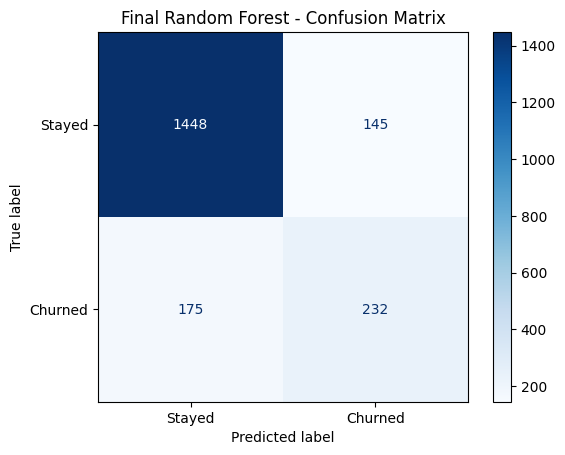

[[1448  145]
 [ 175  232]]


In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot(cmap="Blues")
plt.title("Final Random Forest - Confusion Matrix")
plt.show()

print(cm)

,Feature,Importance
1,num__Age,0.252461
7,num__EstimatedSalary,0.140067
3,num__Balance,0.139128
0,num__CreditScore,0.135254
4,num__NumOfProducts,0.126604
2,num__Tenure,0.082190
6,num__IsActiveMember,0.036510
9,cat__Geography_Germany,0.025982
5,num__HasCrCard,0.018262
8,cat__Geography_France,0.012505


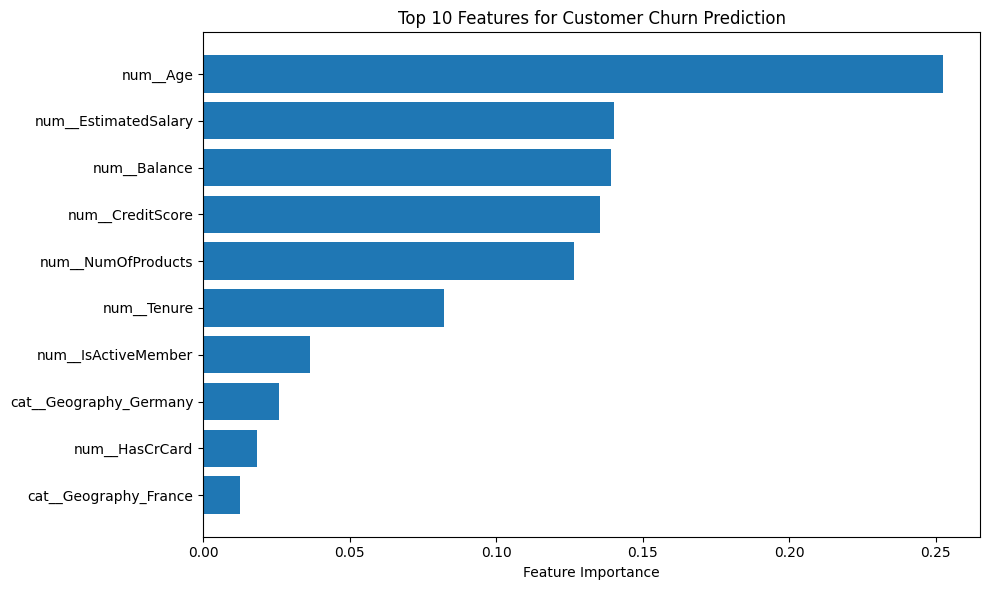

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = (
    final_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get feature importance from Random Forest
importances = final_model.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

top_10 = feature_importance.head(10)

display(top_10)

plt.figure(figsize=(10, 6))
plt.barh(top_10["Feature"][::-1], top_10["Importance"][::-1])
plt.xlabel("Feature Importance")
plt.title("Top 10 Features for Customer Churn Prediction")
plt.tight_layout()
plt.show()

In [32]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Metric": [
        "Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        0.50,
        0.8080,
        0.5891,
        0.1867,
        0.2836,
        0.7748
    ],
    "Random Forest": [
        0.35,
        0.8400,
        0.6154,
        0.5700,
        0.5918,
        0.8508
    ]
})

display(model_comparison.round(4))

,Metric,Logistic Regression,Random Forest
0,Threshold,0.5000,0.3500
1,Accuracy,0.8080,0.8400
2,Precision,0.5891,0.6154
3,Recall,0.1867,0.5700
4,F1-score,0.2836,0.5918
5,ROC-AUC,0.7748,0.8508


### Model Comparison

Random Forest outperformed Logistic Regression across the reported
metrics, including Accuracy, Precision, Recall, F1-score, and ROC-AUC.

The models were evaluated using different classification thresholds:
0.50 for Logistic Regression and 0.35 for Random Forest. The Random
Forest threshold was selected using validation data to balance
Precision and Recall.

Therefore, the threshold-dependent metrics are not a perfectly
like-for-like comparison. ROC-AUC is threshold-independent and provides
a more direct comparison of the models' ability to distinguish between
customers who churn and those who stay.

Random Forest was selected as the final model because it achieved
better overall predictive performance, particularly in identifying
customers likely to churn.

In [33]:
import joblib

joblib.dump(final_model, "churn_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [34]:
from google.colab import files

files.download("churn_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
import os
import joblib

# Save the final trained model
joblib.dump(final_model, "churn_model.joblib")

# Verify the saved model
print("Model saved:", os.path.exists("churn_model.joblib"))
print("Model size:", round(os.path.getsize("churn_model.joblib") / 1024, 2), "KB")

# Test loading the saved model
loaded_model = joblib.load("churn_model.joblib")

print("Model loaded successfully!")
print("Model type:", type(loaded_model).__name__)

Model saved: True
Model size: 40685.7 KB
Model loaded successfully!
Model type: Pipeline


In [36]:
import os

print("Dataset available:", os.path.exists("Churn_Modelling.csv"))

Dataset available: True


In [37]:
import os

print("Dataset shape:", df.shape)
print("Dataset columns:")
print(df.columns.tolist())

df.to_csv("Churn_Modelling.csv", index=False)

print("\nDataset saved successfully!")

Dataset shape: (10000, 14)
Dataset columns:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Dataset saved successfully!


In [40]:
from pathlib import Path
import shutil

project_dir = Path("/content/bank-customer-churn-app")
project_dir.mkdir(parents=True, exist_ok=True)

# Copy the model and dataset into the project folder
for filename in ["churn_model.joblib", "Churn_Modelling.csv"]:
    source = Path("/content") / filename
    destination = project_dir / filename

    if source.exists():
        shutil.copy2(source, destination)
        print(f"Ready: {filename}")
    else:
        print(f"Missing: {filename}")

print("Folder ready:", project_dir.exists())

Ready: churn_model.joblib
Ready: Churn_Modelling.csv
Folder ready: True


In [51]:
import importlib.util

print("google.colab:", importlib.util.find_spec("google.colab") is not None)
print("streamlit:", importlib.util.find_spec("streamlit") is not None)

google.colab: True
streamlit: True


In [99]:
!streamlit run /content/bank-customer-churn-app/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [98]:
!pkill -f streamlit

In [102]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared
!/content/cloudflared tunnel --url http://localhost:8501

^C


In [104]:
from google.colab import files
import shutil

project = "/content/bank-customer-churn-app"
shutil.make_archive(
    "/content/bank-customer-churn",
    "zip",
    project
)

files.download("/content/bank-customer-churn.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [89]:
from pathlib import Path

app_path = Path("/content/bank-customer-churn-app/app.py")
code = app_path.read_text(encoding="utf-8")

old = '''    /* Sidebar navigation buttons */

    [data-testid="stSidebar"] div.stButton > button {{
        background: transparent;
        color: #C5D2E0;
        border: 1px solid transparent;
        border-radius: 9px;
        padding: 0.72rem 0.8rem;
        text-align: left;
        justify-content: flex-start;
        min-height: 46px;
        font-weight: 600;
        box-shadow: none;
        transition: background 0.15s ease;
    }}

    [data-testid="stSidebar"] div.stButton > button:hover {{
        background: rgba(255,255,255,0.08);
        border-color: rgba(255,255,255,0.12);
        color: #FFFFFF;
    }}

    [data-testid="stSidebar"] div.stButton > button[kind="primary"] {{
        background: #FFFFFF;
        color: #1D3354;
        border-color: #FFFFFF;
        font-weight: 750;
    }}

    [data-testid="stSidebar"] div.stButton > button[kind="primary"]:hover {{
        background: #F4F7FB;
        color: #1D3354;
        border-color: #F4F7FB;
    }}'''

new = '''    /* Sidebar navigation buttons — fixed text contrast */

    [data-testid="stSidebar"] div.stButton > button {{
        background-color: transparent !important;
        color: #C5D2E0 !important;
        border: 1px solid transparent !important;
        border-radius: 9px;
        padding: 0.72rem 0.8rem;
        text-align: left;
        justify-content: flex-start;
        min-height: 46px;
        font-weight: 600;
        box-shadow: none !important;
        transition: background 0.15s ease;
    }}

    [data-testid="stSidebar"] div.stButton > button p,
    [data-testid="stSidebar"] div.stButton > button span {{
        color: #C5D2E0 !important;
    }}

    [data-testid="stSidebar"] div.stButton > button:hover {{
        background-color: rgba(255,255,255,0.12) !important;
        border-color: rgba(255,255,255,0.15) !important;
    }}

    [data-testid="stSidebar"] div.stButton > button:hover p,
    [data-testid="stSidebar"] div.stButton > button:hover span {{
        color: #FFFFFF !important;
    }}

    [data-testid="stSidebar"] div.stButton > button[kind="primary"] {{
        background-color: #FFFFFF !important;
        color: #1D3354 !important;
        border-color: #FFFFFF !important;
        font-weight: 750;
    }}

    [data-testid="stSidebar"] div.stButton > button[kind="primary"] p,
    [data-testid="stSidebar"] div.stButton > button[kind="primary"] span {{
        color: #1D3354 !important;
    }}

    [data-testid="stSidebar"] div.stButton > button[kind="primary"]:hover {{
        background-color: #F4F7FB !important;
        color: #1D3354 !important;
        border-color: #F4F7FB !important;
    }}

    /* General buttons — readable white text */

    .stApp div.stButton > button,
    .stApp div.stFormSubmitButton > button {{
        background-color: #1D3354 !important;
        color: #FFFFFF !important;
        border: 1px solid #1D3354 !important;
        border-radius: 9px;
        min-height: 43px;
        font-weight: 650;
        transition: all 0.15s ease;
    }}

    .stApp div.stButton > button p,
    .stApp div.stButton > button span,
    .stApp div.stFormSubmitButton > button p,
    .stApp div.stFormSubmitButton > button span {{
        color: #FFFFFF !important;
    }}

    .stApp div.stButton > button:hover,
    .stApp div.stFormSubmitButton > button:hover {{
        background-color: #467599 !important;
        border-color: #467599 !important;
        color: #FFFFFF !important;
    }}

    .stApp div.stButton > button:hover p,
    .stApp div.stButton > button:hover span,
    .stApp div.stFormSubmitButton > button:hover p,
    .stApp div.stFormSubmitButton > button:hover span {{
        color: #FFFFFF !important;
    }}

    /* Preserve the white selected navigation button */

    [data-testid="stSidebar"] div.stButton > button[kind="primary"],
    [data-testid="stSidebar"] div.stButton > button[kind="primary"]:hover {{
        background-color: #FFFFFF !important;
        color: #1D3354 !important;
        border-color: #FFFFFF !important;
    }}

    [data-testid="stSidebar"] div.stButton > button[kind="primary"] p,
    [data-testid="stSidebar"] div.stButton > button[kind="primary"] span {{
        color: #1D3354 !important;
    }}'''

if old not in code:
    print("لم أغيّر الملف: لم أجد قسم التنسيق الأصلي المطابق، حفاظًا على الكود.")
else:
    code = code.replace(old, new, 1)
    app_path.write_text(code, encoding="utf-8")
    print("تم تعديل ألوان الأزرار داخل app.py مع الحفاظ على بقية الصفحات.")

تم تعديل ألوان الأزرار داخل app.py مع الحفاظ على بقية الصفحات.


In [105]:
import sklearn
print(sklearn.__version__)

1.6.1
